<a href="https://colab.research.google.com/github/aswanth13/AIML/blob/main/randomfor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [14]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [18]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVC

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [7]:
from google.colab import files

uploaded = files.upload()

Saving online food delivery dataset.csv to online food delivery dataset.csv


In [9]:
import pandas as pd

df = pd.read_csv("online food delivery dataset.csv")

print(df.head())

   Age  Gender Marital Status Occupation  Monthly Income  \
0   20  Female         Single    Student       No Income   
1   24  Female         Single    Student  Below Rs.10000   
2   22    Male         Single    Student  Below Rs.10000   
3   22  Female         Single    Student       No Income   
4   22    Male         Single    Student  Below Rs.10000   

  Educational Qualifications  Family size Customer Type  latitude  longitude  \
0              Post Graduate            4      Frequent   12.9766    77.5993   
1                   Graduate            3       Regular   12.9770    77.5773   
2              Post Graduate            3       Regular   12.9551    77.6593   
3                   Graduate            6      Frequent   12.9473    77.5616   
4              Post Graduate            4      Frequent   12.9850    77.5533   

   Pin code Output   Feedback Unnamed: 13  
0    560001    Yes   Positive         Yes  
1    560009    Yes   Positive         Yes  
2    560017    Yes  Negati

In [10]:
print(df.head())
print(df.info())
print(df.describe())

   Age  Gender Marital Status Occupation  Monthly Income  \
0   20  Female         Single    Student       No Income   
1   24  Female         Single    Student  Below Rs.10000   
2   22    Male         Single    Student  Below Rs.10000   
3   22  Female         Single    Student       No Income   
4   22    Male         Single    Student  Below Rs.10000   

  Educational Qualifications  Family size Customer Type  latitude  longitude  \
0              Post Graduate            4      Frequent   12.9766    77.5993   
1                   Graduate            3       Regular   12.9770    77.5773   
2              Post Graduate            3       Regular   12.9551    77.6593   
3                   Graduate            6      Frequent   12.9473    77.5616   
4              Post Graduate            4      Frequent   12.9850    77.5533   

   Pin code Output   Feedback Unnamed: 13  
0    560001    Yes   Positive         Yes  
1    560009    Yes   Positive         Yes  
2    560017    Yes  Negati

In [11]:
X = df.drop("Salary", axis=1)
y = df["Salary"]

KeyError: "['Salary'] not found in axis"

In [12]:
print("Dataset shape:", df.shape)
print(df.head())
print(df.info())

# Remove unwanted duplicate column
df = df.drop(columns=["Unnamed: 13"])

# Remove extra spaces from categorical values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

Dataset shape: (388, 14)
   Age  Gender Marital Status Occupation  Monthly Income  \
0   20  Female         Single    Student       No Income   
1   24  Female         Single    Student  Below Rs.10000   
2   22    Male         Single    Student  Below Rs.10000   
3   22  Female         Single    Student       No Income   
4   22    Male         Single    Student  Below Rs.10000   

  Educational Qualifications  Family size Customer Type  latitude  longitude  \
0              Post Graduate            4      Frequent   12.9766    77.5993   
1                   Graduate            3       Regular   12.9770    77.5773   
2              Post Graduate            3       Regular   12.9551    77.6593   
3                   Graduate            6      Frequent   12.9473    77.5616   
4              Post Graduate            4      Frequent   12.9850    77.5533   

   Pin code Output   Feedback Unnamed: 13  
0    560001    Yes   Positive         Yes  
1    560009    Yes   Positive         Yes  
2

In [15]:
# 2. RANDOM FOREST REGRESSION
# ==================================================

# Predict Age
reg_features = [
    col for col in df.columns
    if col not in ["Age", "Output", "Feedback"]
]

X = df[reg_features]
y = df["Age"]

# Separate categorical and numerical columns
categorical = X.select_dtypes(include="object").columns
numerical = X.select_dtypes(exclude="object").columns

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
        ("num", "passthrough", numerical)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

rf = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        random_state=42
    ))
])

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

print("\n===== RANDOM FOREST REGRESSION =====")

print("MAE:",
      mean_absolute_error(y_test, rf_pred))

print("RMSE:",
      np.sqrt(mean_squared_error(y_test, rf_pred)))

print("R2 Score:",
      r2_score(y_test, rf_pred))



===== RANDOM FOREST REGRESSION =====
MAE: 1.1850975274725277
RMSE: 1.8633763611341885
R2 Score: 0.5270309156745081


In [16]:
# 3. DECISION TREE REGRESSION
# ==================================================

dt = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=8,
        random_state=42
    ))
])

dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

print("\n===== DECISION TREE REGRESSION =====")

print("MAE:",
      mean_absolute_error(y_test, dt_pred))

print("RMSE:",
      np.sqrt(mean_squared_error(y_test, dt_pred)))

print("R2 Score:",
      r2_score(y_test, dt_pred))


===== DECISION TREE REGRESSION =====
MAE: 1.4692420235801773
RMSE: 2.284960012497564
R2 Score: 0.28880482934781704


In [19]:
# 4. SUPPORT VECTOR CLASSIFICATION
# ==================================================

# Predict Output: Yes / No

classification_features = [
    col for col in df.columns
    if col not in ["Output"]
]

X = df[classification_features]
y = df["Output"]

categorical = X.select_dtypes(include="object").columns
numerical = X.select_dtypes(exclude="object").columns

preprocessor_svc = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical),

        ("num", StandardScaler(),
         numerical)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

svc = Pipeline([
    ("preprocessor", preprocessor_svc),

    ("model", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])

svc.fit(X_train, y_train)

svc_pred = svc.predict(X_test)

print("\n===== SUPPORT VECTOR CLASSIFICATION =====")

print("Accuracy:",
      accuracy_score(y_test, svc_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, svc_pred))

print("\nClassification Report:")
print(classification_report(y_test, svc_pred))


===== SUPPORT VECTOR CLASSIFICATION =====
Accuracy: 0.8846153846153846

Confusion Matrix:
[[11  6]
 [ 3 58]]

Classification Report:
              precision    recall  f1-score   support

          No       0.79      0.65      0.71        17
         Yes       0.91      0.95      0.93        61

    accuracy                           0.88        78
   macro avg       0.85      0.80      0.82        78
weighted avg       0.88      0.88      0.88        78



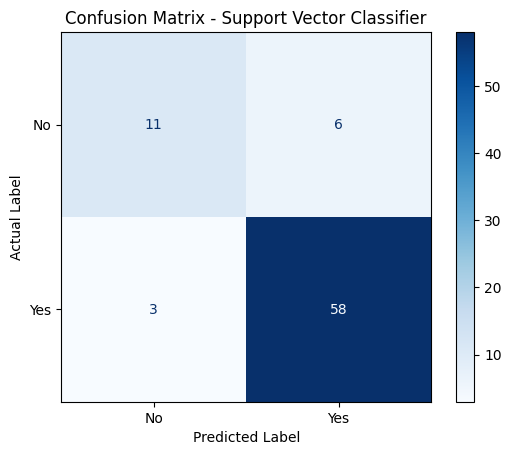

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Create confusion matrix
cm = confusion_matrix(y_test, svc_pred)

# Display as figure
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix - Support Vector Classifier")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()